# 0. Introduction

This notebook documents an end-to-end spatial analytics workflow for Oxford Street,
London: downloading the street network, simplifying its topology, and computing
space syntax centrality measures at multiple distance thresholds.

## Method overview
1. Download the OSM street network for the study area via cityseer's OSM connector.
2. Simplify network topology with neatnet, resolving digitisation artefacts (duplicate
   carriageways, filler nodes, dangling stubs) that distort centrality results if left
   uncleaned.
3. Rebuild the simplified network as a cityseer `CityNetwork` dual graph.
4. Compute shortest-path (metric) and simplest-path (angular) centrality across
   several distance thresholds, spanning pedestrian scale (400–1600m) through a
   wider city-scale comparison (2000–10000m).

## Runtime note
Centrality computation over the full distance set takes roughly 60–90 minutes on
~62,500 street segments (this run: ~35 min shortest-path, ~51 min simplest-path).
Budget accordingly, or reduce `DISTANCES` in `config.py` for a faster test run.

## Data provenance
OSM data was pulled on **6 August 2026**. OSM is a live, continuously-edited
dataset. Re-running this notebook at a later date may return a different network.

## File handling
Raw and neatnet-simplified networks are stored under `RAW_DATA`; computed centrality
results and the serialised `CityNetwork` state are stored under `OUTPUTS_DIR`, both
under the project's `data/` directory (see `config.py`).


# 1. Imports

In [1]:
import os
import sys
from pathlib import Path

# This really helps with organization of the project
repo_root = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd().parents[1]
if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

# Importing libraries and third party packages
import geopandas as gpd
import cityseer
import pandas as pd
import neatnet as nt
import matplotlib.pyplot as plt
from shapely.geometry import box
from pathlib import Path

# Custom imports for each case
from modules.config import (
    BBOX, 
    RAW_DATA, 
    OUTPUTS_DIR, DISTANCES
)

c:\Users\delag\miniforge3\envs\spatial-analytics\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 2. Downloading the raw network

Downloads the OSM street network within `BBOX` (defined in `config.py`) via
cityseer's `from_osm` constructor, which also runs cityseer's own OSM-tuned
cleaning pass (junction consolidation, parallel carriageway merging, ironing)
before the network is handed off to neatnet in the next step.

In [2]:
# bring in the bounding box. the asterisk is for parsing the BBOX dic
polygon = box(*BBOX)

un = (
    cityseer.CityNetwork.from_osm(polygon)
)

# Persist the raw (pre-neatnet) network so later experimentation with
# simplification parameters doesn't require re-downloading from OSM.
raw_path = os.path.join(RAW_DATA, "network_raw.gpkg")
un.to_geopandas().to_file(raw_path, driver="GPKG")

#printing output the number of segments in the model
print(f"{un.node_count} street segments")

INFO:cityseer.tools.graphs:Generating interpolated edge geometries.
100%|██████████| 623757/623757 [00:07<00:00, 87665.49it/s] 
INFO:cityseer.tools.io:Converting networkX graph to CRS code 32630.
INFO:cityseer.tools.io:Processing node x, y coordinates.
100%|██████████| 575097/575097 [00:01<00:00, 314790.26it/s]
INFO:cityseer.tools.io:Processing edge geom coordinates, if present.
100%|██████████| 623757/623757 [01:38<00:00, 6364.52it/s] 
INFO:cityseer.tools.graphs:Removing filler nodes.
100%|██████████| 575097/575097 [00:32<00:00, 17565.30it/s]
INFO:cityseer.tools.util:Creating edges STR tree.
100%|██████████| 249671/249671 [00:45<00:00, 5457.43it/s]
INFO:cityseer.tools.graphs:Removing filler nodes.
100%|██████████| 182613/182613 [00:01<00:00, 157281.59it/s]
INFO:cityseer.tools.graphs:Removing dangling nodes.
INFO:cityseer.tools.graphs:Removing filler nodes.
100%|██████████| 177860/177860 [00:00<00:00, 510176.12it/s]
INFO:cityseer.tools.util:Creating edges STR tree.
100%|██████████| 152

89486 street segments


# 3. Simplifying with neatnet

`un.to_geopandas()` exports cityseer's cleaned primal edges as a GeoDataFrame.
neatnet's `neatify()` resolves topology issues cityseer's OSM cleaning doesn't
target — principally dual carriageways and complex junctions collapsing to a
single centreline. Output is saved to `RAW_DATA/network.gpkg`.

In [3]:
print(f"Segments before neatnet: {len(un.to_geopandas())}")

network = un.to_geopandas()
network = nt.neatify(network)

print(f"Segments after neatnet: {len(network)}")

#saving the results to the downloads path
output_path = os.path.join(RAW_DATA, "network.gpkg")
network.to_file(output_path, driver="GPKG")

Segments before neatnet: 89486


c:\Users\delag\miniforge3\envs\spatial-analytics\Lib\site-packages\neatnet\simplify.py:881: UserWarning: No threshold for artifact detection found. Using the set fallback value of 7.
  artifacts, threshold = get_artifacts(
c:\Users\delag\miniforge3\envs\spatial-analytics\Lib\site-packages\neatnet\geometry.py:269: UserWarning: Could not create a connection as it would lead outside of the artifact.
  additions, splits = snap_to_targets(
c:\Users\delag\miniforge3\envs\spatial-analytics\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
c:\Users

Segments after neatnet: 62454


INFO:pyogrio._io:Created 62,454 records


# 4. Creating the dual-graph

cityseer's `CityNetwork` builds a dual graph (street segments become nodes,
intersections become edges), enabling both metric and angular centrality analysis.

**Note:** neatnet's output carries internal bookkeeping columns (nullable-boolean
dtype) that break cityseer's column-merging step on construction. Only `geometry`
is passed through below — see [`from_geopandas` API notes] for column-handling
details if you want to carry real attributes (e.g. street names) forward.

`remove_danglers=10.0` and `merge_parallel_dist=2.0` are cityseer's defaults;
retained here since neatnet's simplification already resolves most topology
issues upstream, so this step should have little left to do — `feature_status`
below confirms that (62,502 active vs. 38 merged/duplicate/dangler/loop out of
62,540 input features).

In [4]:
# Keep geometry only — drop neatnet's internal bookkeeping columns.
# Adjust the keep-list if you're carrying real attributes (e.g. a street name column).
keep_cols = ["geometry"]
network_clean = network[keep_cols].copy()

cn = cityseer.CityNetwork.from_geopandas(
    network_clean,
    crs=32630,
    remove_fillers=True,
    remove_danglers=10.0,
    merge_parallel_dist=2.0,
)

print(cn.feature_status.value_counts())
print(f"{cn.node_count} dual nodes (street segments)")

Building edges: 100%|██████████| 130477/130477 [00:05<00:00, 21950.34it/s]
INFO:cityseer.graph:Edge R-tree built successfully with 130477 items.
INFO:cityseer.graph:Street R-tree built with 62415 items.


feature_status
active             62415
merged                15
duplicate              8
short_dangler          8
short_self_loop        8
Name: count, dtype: int64
62415 dual nodes (street segments)


# 5. Calculating centrality measures

Two families of centrality are computed at each threshold in `DISTANCES`
(`config.py`):

- **`centrality_shortest`** — metric (shortest-path) closeness and betweenness.
  Distance is measured as physical street length.
- **`centrality_simplest`** — angular (simplest-path) closeness and betweenness,
  suffixed `_ang`. Distance is measured as cumulative angular deviation, closer
  to classic space syntax "integration."

Both default to `cc_harmonic_{d}` (closeness) and `cc_betweenness_{d}` — see the
[cityseer centrality guide] for the full metric set (density, farness, Hillier
normalisation, cycles) if a fuller comparison is wanted later.

In [5]:
# Metric centrality — standard space syntax "integration"-adjacent measures
cn.centrality_shortest(distances=DISTANCES)

# Angular centrality — closer to classic space syntax "integration" (simplest path)
cn.centrality_simplest(distances=DISTANCES)

INFO:cityseer.metrics.networks:Computing centrality (shortest).
INFO:cityseer.metrics.networks:  Full: 400m, 800m, 1600m, 2000m, 5000m, 10000m
centrality full: 400m, 800m, 1600m, 2000m, 5000m, 10000m: 100%|██████████| 62415/62415 [03:19<00:00, 312.66it/s]
INFO:cityseer.metrics.networks:Computing centrality (simplest).
INFO:cityseer.metrics.networks:  Full: 400m, 800m, 1600m, 2000m, 5000m, 10000m
centrality simplest full: 400m, 800m, 1600m, 2000m, 5000m, 10000m: 100%|██████████| 62415/62415 [09:48<00:00, 105.99it/s]


CityNetwork(node_count=62415, is_dual=True, is_directed=False, crs=EPSG:32630)

# 6. Saving the results

Exports the full centrality result set with original LineString geometries to
`OUTPUTS_DIR/network_centrality.gpkg` (portable, GIS-inspectable), and separately
persists the `CityNetwork`'s internal state via `cn.save()` (parquet + pickle) so
the object can be restored without recomputation.

In [7]:
# Full metric round-trip export with original LineString geometries
result_gdf = cn.to_geopandas()
result_gdf.to_file(os.path.join(OUTPUTS_DIR, "network_centrality.gpkg"), driver="GPKG")

# Also save the CityNetwork's internal state (parquet + pickle) so you don't
# have to recompute if you come back to this later
cn.save(os.path.join(OUTPUTS_DIR, "cn_oxford_street.gpkg"))

INFO:pyogrio._io:Created 62,415 records


# 7. Visualising results

A first look at the computed centrality surfaces; metric closeness at a
pedestrian-scale threshold, and a metric-vs-angular comparison at the same
distance, to illustrate how the two path definitions diverge.

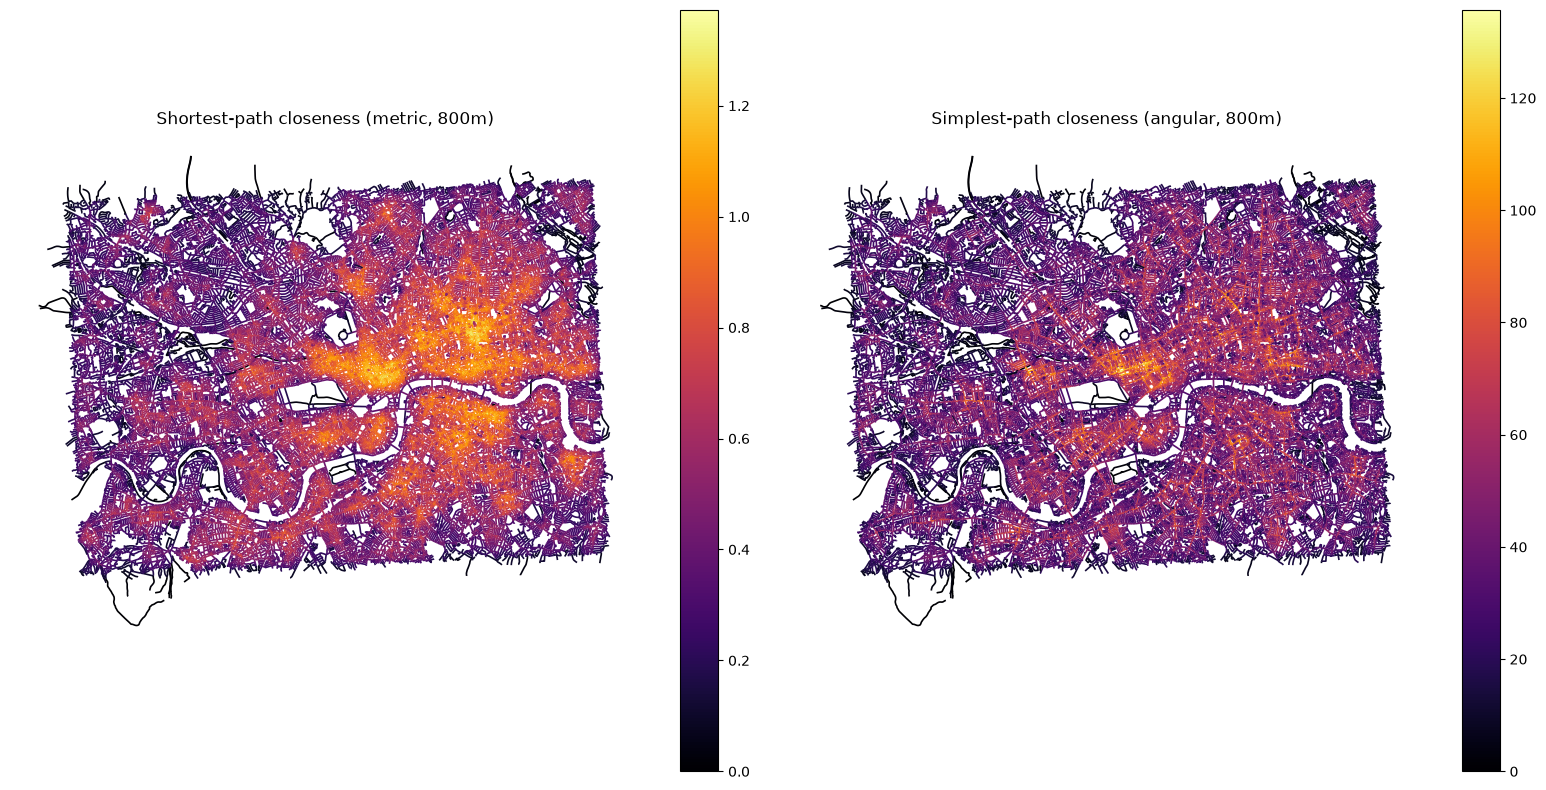

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

result_gdf.plot(column="cc_harmonic_800", 
                cmap="inferno", 
                linewidth=1.2, 
                legend=True, 
                ax=axes[0])
axes[0].set_title("Shortest-path closeness (metric, 800m)")
axes[0].set_axis_off()

result_gdf.plot(column="cc_harmonic_800_ang", 
                cmap="inferno", 
                linewidth=1.2, 
                legend=True, 
                ax=axes[1])

axes[1].set_title("Simplest-path closeness (angular, 800m)")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()